# Макроэкономические показатели Росстата

Самостоятельный блокнот: установка зависимостей → загрузка источников → разбор → проверки → графики → признаки и CSV.
Все ссылки и код находятся здесь. Дополнительно нужен только `certificates/rosstat_ca_bundle.pem`.
Запустите **Run All** в Python 3.12+; первый запуск скачает файлы, последующие используют кеш.

Срез источников — октябрь 2026 года. Собираем потребительские цены, базовый ИПЦ,
цены производителей, промпроизводство, номинальную и реальную зарплату, безработицу, розницу, платные услуги,
реальные доходы населения, инвестиции и ВВП. Базовый ИПЦ собран по отдельным
выпускам за 2025–2026 годы; остальные диапазоны показаны в отчёте качества.

Индексы с базой 100 сохраняются как индексы. Кварталы хранятся отдельно от месяцев;
текущие таблицы могут содержать пересмотренные значения. Для сопоставления с решениями
ЦБ нужны исторические даты публикаций и версии данных на момент решения.

## 1. Зависимости
Устанавливаются в среду текущего ядра. Jupyter должен быть уже запущен.

In [1]:
%pip install --quiet --disable-pip-version-check requests==2.34.2 pandas==3.1.0 openpyxl==3.1.5 xlrd==2.0.2 beautifulsoup4==4.15.0 matplotlib==3.11.2 pypdf==6.21.4

Note: you may need to restart the kernel to use updated packages.


## 2. Настройки и источники
`ALLOW_NETWORK=False` запрещает новые загрузки; `REFRESH=True` обновляет снимки.
Исходные Excel и HTML сохраняются с понятными именами в `data/raw/`, результаты — в новой папке `data/processed/`.
Файлы на сайте зафиксированы явно: при появлении нового выпуска ссылки и структуру нужно проверить.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin, urlparse
import hashlib
import json
import math
import re
import time
import warnings

import pandas as pd
import requests
from bs4 import BeautifulSoup
from pypdf import PdfReader
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'certificates/rosstat_ca_bundle.pem').is_file():
    raise RuntimeError('Откройте блокнот из папки проекта рядом с certificates/')
RAW = ROOT / 'data/raw'
RAW.mkdir(parents=True, exist_ok=True)
OUT = ROOT / 'data/processed' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
ALLOW_NETWORK = True
REFRESH = False
BASE_URL = 'https://rosstat.gov.ru/storage/mediabank/'
MONTHS = 'январь февраль март апрель май июнь июль август сентябрь октябрь ноябрь декабрь'.split()

FILES = {
    'cpi': 'ipc_mes_09-2026.xlsx',
    'cpi_check': 'ipc_RF_fo_sub_09-2026.xlsx',
    'ppi': 'Proizvoditeli_Ind_VED_09-2026.xlsx',
    'wages': 'tab1-zpl_08-2026.xlsx',
    'retail': 'Oborot_m_09-2026.xlsx',
    'gdp': 'VVP_kvartal_s-1995-2026.xlsx',
    'industry': 'ind_baza_2023_09-2026.xlsx',
    'unemployment': 'Trud-3_15-s.xlsx',
    'income': 'urov_12kv_3kv2026.xlsx',
    'investment': 'Inv_reg_kv_2020_2026.xlsx',
    'report': 'osn-09-2026.pdf',
    'report_2025': 'osn-01-2025.pdf',
    'report_2024': 'osn-11-2024.pdf',
}
# Выпуски с базовым ИПЦ: год и месяц показателя, файл (с датой публикации в имени).
CORE_RELEASES = {
    2025: ['19_14-02-2025.html', '34_12-03-2025.html', '53_11-04-2025.html',
           '70_16-05-2025.html', '85_11-06-2025.html', '105_11-07-2025.html',
           '120_13-08-2025.html', '137_10-09-2025.html', '157_10-10-2025.html',
           '174_14-11-2025.html', '189_10-12-2025.html', '3_16-01-2026.html'],
    2026: ['19_13-02-2026.html', '34_13-03-2026.html', '53_10-04-2026.html',
           '68_15-05-2026.html', '84_10-06-2026.html', '105_10-07-2026.html',
           '120_12-08-2026.html', '140_11-09-2026.html', '157_09-10-2026.html'],
}
CORE = [(year, month, name) for year, names in CORE_RELEASES.items()
        for month, name in enumerate(names, 1)]
SERVICE_FILES = {
    2022: [
        'plat_012022.xls', 'plat_022022.xls', 'plat_032022.xls',
        'plat_042022.xls', 'plat_052022.xls', 'plat_062022.xls',
        'plat_072022.xls', 'plat_082022.xls', 'plat_092022.xls',
        'plat_102022.xls', 'plat_112022.xls', 'Plat_122022.xls',
    ],
    2023: [
        'Plat_012023.xls', 'Plat_022023.xls', 'Plat_032023.xls',
        'Plat_042023.xls', 'Plat_052023.xls', 'Plat_062023.xls',
        'Plat_072023.xls', 'Plat_082023.xls', 'Plat_092023.xls',
        'Plat_102023.xls', 'Plat_112023.xls', 'Plat_122023.xls',
    ],
    2024: [
        'plat_012024.xls', 'plat-022024.xls', 'plat_032024.xls',
        'plat_042024.xls', 'plat-052024.xls', 'Plat_062024.xls',
        'Plat_072024.xls', 'Plat_082024.xls', 'plat_092024.xls',
        'plat_102024.xls', 'plat_112024.xls', 'Plat_122024.xls',
    ],
    2025: [
        'plat_01_2025.xls', 'plat_02_2025.xls', 'plat_03_2025.xls',
        'plat_04_2025.xls', 'plat_05_2025.xls', 'plat_06_2025.xls',
        'plat_07_2025.xls', 'plat_08_2025.xls', 'plat_09_2025.xls',
        'plat_10_2025.xls', 'plat_11_2025.xls', 'plat_12_2025.xls',
    ],
    2026: [
        'plat_01_2026.xls', 'plat_02_2026.xls', 'plat_03_2026.xls',
        'plat_04_2026.xls', 'plat_05_2026.xls', 'plat_06_2026.xls',
        'plat_07_2026.xls', 'plat_08_2026.xls', 'plat_092026.xls',
    ],
}
SERVICES = [(year, month, name) for year, names in SERVICE_FILES.items()
            for month, name in enumerate(names, 1)]
FILE_NAMES = list(FILES.values()) + [name for _, _, name in SERVICES + CORE]
print(f'Источников: {len(FILE_NAMES)}; выпуски услуг: {len(SERVICES)}, ИПЦ: {len(CORE)}')

Источников: 91; выпуски услуг: 57, ИПЦ: 21


## 3. Загрузка источников
TLS проверяется с официальной цепочкой Минцифры из папки `certificates/`.
Для каждого файла сохраняются URL, SHA-256 и время получения. При чтении кеша проверяется хеш.
При ошибке загрузки или изменении формата выполнение останавливается.

In [3]:
http = requests.Session()
http.verify = str(ROOT / 'certificates/rosstat_ca_bundle.pem')
http.headers['User-Agent'] = 'rosstat-macro-research/1.0'
manifest_path = RAW / 'downloads.json'
metadata = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}


def download(name):
    path, url = RAW / name, BASE_URL + name
    if path.exists() and not REFRESH:
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        if name in metadata and metadata[name]['sha256'] != digest:
            raise ValueError(f'Изменился кеш {name}: загрузите заново с REFRESH=True')
        metadata.setdefault(name, dict(url=url, sha256=digest, retrieved_at=None,
                                       acquisition='local_file'))
        return path
    if not ALLOW_NETWORK:
        raise FileNotFoundError(f'Нет {name}; разрешите сеть или положите файл в {RAW}')
    response = http.get(url, timeout=(15, 90), allow_redirects=False)
    for _ in range(5):
        if response.status_code not in (301, 302, 303, 307, 308):
            break
        url = urljoin(url, response.headers['Location'])
        if urlparse(url).scheme != 'https' or urlparse(url).hostname not in {'rosstat.gov.ru', 'www.rosstat.gov.ru'}:
            raise ValueError(f'Неожиданное перенаправление: {url}')
        response = http.get(url, timeout=(15, 90), allow_redirects=False)
    response.raise_for_status()
    payload = response.content
    if name.endswith('.xlsx'):
        valid = payload.startswith(b'PK\x03\x04')
    elif name.endswith('.xls'):
        valid = payload.startswith(bytes.fromhex('D0CF11E0A1B11AE1'))
    elif name.endswith('.pdf'):
        valid = payload.startswith(b'%PDF-')
    elif name.endswith('.html'):
        valid = b'<html' in payload[:2000].lower() or b'<!doctype html' in payload[:2000].lower()
    else:
        raise ValueError(f'Неизвестный формат: {name}')
    if response.status_code != 200 or not valid:
        raise ValueError(f'{name}: получен ответ неожиданного формата')
    temporary = path.with_suffix(path.suffix + '.part')
    temporary.write_bytes(payload)
    temporary.replace(path)
    metadata[name] = dict(url=BASE_URL + name, sha256=hashlib.sha256(payload).hexdigest(),
                          retrieved_at=datetime.now(timezone.utc).isoformat(),
                          acquisition='https_download')
    manifest_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
    time.sleep(0.3)
    return path


paths = {name: download(name) for name in FILE_NAMES}
manifest_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
print(f'Готово: {len(paths)} файлов. Кеш: {RAW}')

Готово: 91 файлов. Кеш: /Users/oleynik_n_a/Documents/ChatGPT/Годовой проект/data/raw


## 4. Общие функции для чтения таблиц
Пропуски сохраняются, неизвестные числовые пометки вызывают ошибку.
Контрольные заголовки защищают от незаметной смены структуры таблиц.

In [4]:
def text(value):
    if pd.isna(value):
        return ''
    return re.sub(r'\s+', ' ', str(value).replace('\xa0', ' ').replace('\u202f', ' ')).strip()


def number(value):
    label = text(value).lower().replace(' ', '').replace(',', '.').replace('−', '-')
    if label in {'', '-', '–', '—', '...', '…', 'н/д', 'н.д.', 'nan', 'none'}:
        return float('nan')
    if not re.fullmatch(r'[+-]?\d+(?:\.\d+)?', label):
        raise ValueError(f'Нераспознанное число: {value!r}')
    return float(label)


def year_number(value):
    label = text(value)
    if re.fullmatch(r'(?:19|20)\d{2}(?:\.0|\s*г\.?)?(?:\s*(?:\(\d+\)|\d+\)|\*+))?', label):
        return int(label[:4])
    return None


def expect(frame, row, column, label, contains=False):
    actual = text(frame.iat[row, column])
    if not (label.casefold() in actual.casefold() if contains else actual.casefold() == label.casefold()):
        raise ValueError(f'Изменился заголовок [{row}, {column}]: {actual!r}; ожидалось {label!r}')


source_notes = set()
parts = []


def read_excel(name, sheet):
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='The xlrd engine is deprecated.*')
        frame = pd.read_excel(paths[name], sheet_name=sheet, header=None, dtype=object)
    for value in frame.to_numpy().ravel():
        label = text(value)
        if len(label) > 70 and re.search('Без учета|учетом|деноминац|пересматрив|Данные содержат', label, re.I):
            source_notes.add((name, sheet, label))
    return frame


def add_series(records, indicator, frequency, unit, basis, name, sheet, note=''):
    result = pd.DataFrame(records, columns=['period', 'value']).sort_values('period')
    observed = result.loc[result.value.notna(), 'period']
    if observed.empty or result.period.duplicated().any():
        raise ValueError(f'{indicator}: нет значений или повторяются периоды')
    if not all(math.isfinite(v) for v in result.value.dropna()):
        raise ValueError(f'{indicator}: бесконечные значения')
    result = result.loc[result.period.between(observed.min(), observed.max())].copy()
    for key, value in dict(indicator=indicator, frequency=frequency, unit=unit, basis=basis,
                           source_url=BASE_URL + name,
                           source_sha256=metadata[name]['sha256'], sheet=sheet,
                           retrieved_at=metadata[name]['retrieved_at'],
                           acquisition=metadata[name]['acquisition'], methodology_note=note).items():
        result[key] = value
    result['release_date'] = pd.NaT
    parts.append(result)

## 5. ИПЦ: общий индекс и три группы
На листах `01`–`04` годы расположены по столбцам, отдельные месяцы — по строкам.
Берём только блок «к концу предыдущего месяца», исключая итог к декабрю прошлого года.

In [5]:
CPI_INDICATORS = ['cpi_mom_index', 'cpi_food_mom_index',
                  'cpi_nonfood_mom_index', 'cpi_services_mom_index']
name = FILES['cpi']
for sheet, indicator in zip(['01', '02', '03', '04'], CPI_INDICATORS):
    frame = read_excel(name, sheet)
    expect(frame, 0, 0, 'Индексы потребительских цен', contains=True)
    expect(frame, 0, 0, 'Российской Федерации', contains=True)
    expect(frame, 4, 0, 'к концу предыдущего месяца')
    records = []
    for column, year in enumerate(range(1991, 2027), 1):
        if year_number(frame.iat[3, column]) != year:
            raise ValueError(f'Изменился год ИПЦ: столбец {column}')
        for month in range(1, 13):
            row = month + 4
            expect(frame, row, 0, MONTHS[month - 1])
            records.append((pd.Timestamp(year=year, month=month, day=1), number(frame.iat[row, column])))
    add_series(records, indicator, 'monthly', '%', 'предыдущий месяц = 100', name, sheet,
               'Индекс на конец месяца; территориальные оговорки сохранены в source_notes.csv.')
print('ИПЦ: извлечены 4 ряда.')

ИПЦ: извлечены 4 ряда.


## 6. Цены производителей
Используем единую классификацию ОКВЭД2 с 2013 года. Исторические данные — на листах
`2.1`–`2.3`, месяцы 2026 года — на листе `8.1` в строке РФ внутри каждой отрасли.
Старые данные ОКВЭД-2007 не присоединяются.

In [6]:
name = FILES['ppi']
current = read_excel(name, '8.1')
expect(current, 0, 0, '2026', contains=True)
expect(current, 1, 0, 'к предыдущему месяцу', contains=True)
for sheet, slug, sector, code_value in [
    ('2.1', 'industry', 'Промышленность', '1323500.029.31'),
    ('2.2', 'mining', 'Добыча полезных ископаемых', 'B'),
    ('2.3', 'manufacturing', 'Обрабатывающие производства', 'C'),
]:
    frame = read_excel(name, sheet)
    expect(frame, 0, 1, 'ОКВЭД2', contains=True)
    expect(frame, 0, 1, sector, contains=True)
    expect(frame, 3, 0, 'К предыдущему месяцу')
    records = []
    for column, year in enumerate(range(2013, 2026), 1):
        if year_number(frame.iat[2, column]) != year:
            raise ValueError(f'Изменился год цен производителей: {sheet}, {column}')
        for month in range(1, 13):
            row = month + 3
            expect(frame, row, 0, MONTHS[month - 1])
            records.append((pd.Timestamp(year=year, month=month, day=1), number(frame.iat[row, column])))
    add_series(records, f'ppi_{slug}_mom_index', 'monthly', '%', 'предыдущий месяц = 100',
               name, sheet, 'ОКВЭД2; товары для реализации на внутреннем рынке.')
    records = []
    matches = current.index[current[1].map(text).eq(code_value)].tolist()
    if len(matches) != 1:
        raise ValueError(f'Не найдена однозначная отрасль: {sector}')
    row = matches[0] + 1
    expect(current, row, 0, 'Российская Федерация')
    for month in range(1, 10):
        expect(current, 2, month + 1, MONTHS[month - 1])
        records.append((pd.Timestamp(year=2026, month=month, day=1), number(current.iat[row, month + 1])))
    add_series(records, f'ppi_{slug}_mom_index', 'monthly', '%', 'предыдущий месяц = 100',
               name, '8.1', 'ОКВЭД2; товары для реализации на внутреннем рынке.')
print('Цены производителей: извлечены 3 ряда.')

Цены производителей: извлечены 3 ряда.


## 7. Номинальная зарплата
Берём месяцы с 1998 года: более ранние значения выражены в тысячах рублей.
Средние за год и квартал исключены. В трёх ячейках конца 2022 года отдельно
обработана сноска `(2)`; её территориальное пояснение сохранено.

In [7]:
name, sheet = FILES['wages'], 'Лист1'
frame = read_excel(name, sheet)
expect(frame, 0, 0, 'номинальная начисленная заработная плата', contains=True)
expect(frame, 1, 0, 'в целом по экономике Российской Федерации', contains=True)
expect(frame, 3, 0, 'Рублей', contains=True)
footnoted = {(38, 15): '62 470(2)', (38, 16): '63 060(2)', (38, 17): '88 468(2)'}
records = []
for row, expected_year in zip(range(14, 43), range(1998, 2027)):
    year = year_number(frame.iat[row, 0])
    if year != expected_year:
        raise ValueError(f'Изменился год зарплаты: строка {row}')
    for month in range(1, 13):
        column = month + 5
        expect(frame, 4, column, MONTHS[month - 1])
        value = frame.iat[row, column]
        if (row, column) in footnoted:
            if text(value) != footnoted[row, column]:
                raise ValueError('Изменилась проверенная ячейка зарплаты со сноской')
            value = text(value).removesuffix('(2)')
        records.append((pd.Timestamp(year=year, month=month, day=1), number(value)))
add_series(records, 'nominal_wages_rub', 'monthly', 'рублей',
           'номинальная начисленная зарплата, рублей в месяц', name, sheet,
           'Ряд с 1998 года; территориальные изменения см. source_notes.csv.')
print('Зарплата: извлечён 1 ряд.')

Зарплата: извлечён 1 ряд.


## 8. Розничная торговля
Текущий файл содержит только номинальный оборот за месяцы 2026 года.
Строки «январь–март» и другие накопительные итоги исключаются.
Годовой файл `IFO_rozn_2025.xls` не используется как месячный показатель.

In [8]:
name, sheet = FILES['retail'], '1'
frame = read_excel(name, sheet)
expect(frame, 2, 0, 'Оборот розничной торговли по месяцам по Российской Федерации, млн.руб.')
expect(frame, 4, 1, 'всего')
if year_number(frame.iat[6, 0]) != 2026:
    raise ValueError('Изменился год оборота розницы')
records = []
for row in range(8, 30):
    label = text(frame.iat[row, 0]).lower()
    if label in MONTHS:
        month = MONTHS.index(label) + 1
        records.append((pd.Timestamp(year=2026, month=month, day=1), number(frame.iat[row, 1])))
add_series(records, 'retail_turnover_nominal_mln_rub', 'monthly', 'млн рублей',
           'оборот за отдельный месяц в текущих ценах', name, sheet,
           'Текущие цены; это не индекс физического объёма.')
print('Розница: извлечён 1 ряд.')

Розница: извлечён 1 ряд.


## 9. Физический объём платных услуг
Собираем отдельные месячные выпуски с января 2022 по сентябрь 2026.
В старых книгах строка России находится на одну строку ниже из-за дополнительной
нумерации столбцов; проверяются оба известных формата и база каждого индекса.
Накопительный индекс к соответствующему периоду прошлого года исключается.

In [9]:
sheet = 'платные всего'
for year, month, name in SERVICES:
    frame = read_excel(name, sheet)
    expect(frame, 1, 0, 'Основные показатели платных услуг населению', contains=True)
    expect(frame, 1, 0, f'{MONTHS[month - 1]} {year}', contains=True)
    expect(frame, 2, 0, 'Платные услуги населению')
    expect(frame, 4, 2, 'Индекс физического объема', contains=True)
    rows = [r for r in (6, 7) if re.fullmatch(
        r'(?:Россия|Российская Федерация)(?:\*+|\d+\)|\(\d+\))?', text(frame.iat[r, 0]))]
    if len(rows) != 1:
        raise ValueError(f'Не найдена однозначная строка России: {name}')
    for column, slug, header, basis in [
        (2, 'mom', 'предыдущему месяцу', 'предыдущий месяц = 100'),
        (3, 'yoy', 'соответствующему месяцу прошлого года', 'соответствующий месяц предыдущего года = 100'),
    ]:
        expect(frame, 5, column, header)
        add_series([(pd.Timestamp(year=year, month=month, day=1), number(frame.iat[rows[0], column]))],
                   f'paid_services_volume_{slug}_index', 'monthly', '%', basis, name, sheet,
                   'Отдельные выпуски; история может отличаться от позднейших пересмотренных рядов.')
print(f'Услуги: 2 ряда из {len(SERVICES)} месячных выпусков.')

Услуги: 2 ряда из 57 месячных выпусков.


## 10. Квартальный ВВП
Используем современные листы с единой методологией. Постоянные цены 2021 года
сохраняются отдельно от индекса к соответствующему кварталу предыдущего года.
Кварталы не интерполируются в месяцы.

In [10]:
name = FILES['gdp']
quarters = ['I квартал', 'II квартал', 'III квартал', 'IV квартал']
for sheet, indicator, unit, basis, start_year in [
    ('9', 'gdp_real_2021_bln_rub', 'млрд рублей', 'постоянные цены 2021 года', 2011),
    ('10', 'gdp_real_2021_sa_bln_rub', 'млрд рублей', 'постоянные цены 2021 года, сезонная корректировка', 2011),
    ('12', 'gdp_volume_yoy_index', '%', 'соответствующий квартал предыдущего года = 100', 2012),
]:
    frame = read_excel(name, sheet)
    if sheet == '12':
        expect(frame, 1, 0, 'Индексы физического объема валового внутреннего продукта', contains=True)
        expect(frame, 1, 0, 'к соответствующему кварталу предыдущего года', contains=True)
    else:
        expect(frame, 1, 0, 'в ценах 2021г., млрд.руб.', contains=True)
        if ('с исключением сезонного фактора' in text(frame.iat[1, 0])) != (sheet == '10'):
            raise ValueError('Изменился вариант сезонной корректировки ВВП')
    records = []
    for column in range(frame.shape[1]):
        year, quarter = start_year + column // 4, column % 4 + 1
        if year_number(frame.iat[2, column - column % 4]) != year:
            raise ValueError(f'Изменился год ВВП: {sheet}, {column}')
        expect(frame, 3, column, quarters[quarter - 1])
        records.append((pd.Timestamp(year=year, month=quarter * 3 - 2, day=1), number(frame.iat[4, column])))
    add_series(records, indicator, 'quarterly', unit, basis, name, sheet,
               'Современная методология; старые листы с другими базовыми ценами не присоединяются.')
print('ВВП: извлечены 3 квартальных ряда.')

ВВП: извлечены 3 квартальных ряда.


## Базовый ИПЦ
Отдельные федеральные выпуски за январь 2025 — сентябрь 2026 года.
Берём индекс к предыдущему месяцу и к тому же месяцу прошлого года, проверяя
заголовки таблицы и общий ИПЦ по ранее извлечённой книге. Даты выпуска берём из имён
официальных публикаций; время публикации в течение дня не указано.

In [11]:
for year, month, name in CORE:
    soup = BeautifulSoup(paths[name].read_bytes(), 'html.parser')
    matches = []
    for row in soup.find_all('tr'):
        cells = [' '.join(cell.stripped_strings) for cell in row.find_all(['td', 'th'], recursive=False)]
        if cells and text(cells[0]).casefold() == 'базовый индекс потребительских цен':
            matches.append((row, cells))
    if len(matches) != 1:
        raise ValueError(f'{name}: строка базового ИПЦ не найдена однозначно')
    row, cells = matches[0]
    table = row.find_parent('table')
    heading = text(table.get_text(' ', strip=True)).lower()
    if f'{MONTHS[month-1]} {year}' not in heading:
        raise ValueError(f'{name}: не совпал месяц выпуска')
    rows = []
    for tr in table.find_all('tr'):
        cols = [' '.join(c.stripped_strings) for c in tr.find_all(['td', 'th'], recursive=False)]
        if cols and text(cols[0]).casefold() == 'индекс потребительских цен':
            rows.append(cols)
    if len(rows) != 1:
        raise ValueError(f'{name}: не найдена контрольная строка общего ИПЦ')
    period = pd.Timestamp(year=year, month=month, day=1)
    cpi_month = parts[0].set_index('period').loc[period, 'value']
    if not math.isclose(number(rows[0][1]), cpi_month, abs_tol=0.011):
        raise ValueError(f'{name}: общий ИПЦ не совпал с книгой месячных индексов')
    match = re.search(r'_(\d{2}-\d{2}-\d{4})\.html$', name)
    if not match:
        raise ValueError(f'{name}: не найдена дата выпуска')
    release_date = pd.to_datetime(match.group(1), format='%d-%m-%Y')
    if release_date <= period + pd.offsets.MonthEnd():
        raise ValueError(f'{name}: дата выпуска раньше конца отчётного месяца')
    for indicator, column, basis in [
        ('core_cpi_mom_index', 1, 'предыдущий месяц = 100'),
        ('core_cpi_yoy_index', 2 if month in (1, 12) else 3, 'соответствующий месяц предыдущего года = 100'),
    ]:
        value = number(cells[column])
        add_series([(period, value)], indicator, 'monthly', '%', basis, name,
                   'таблица Индексы потребительских цен',
                   'Федеральный выпуск; дата из имени файла, время публикации не установлено.')
        parts[-1]['release_date'] = release_date
print(f'Базовый ИПЦ: {len(CORE)} выпусков, два индекса в каждом.')

Базовый ИПЦ: 21 выпусков, два индекса в каждом.


## Промышленное производство
Индексы в % к предыдущему и соответствующему месяцу прошлого года.
ОКВЭД2, текущая база 2023 года; ряд начинается с 2020 года в данной книге.
Не смешиваем с данными других баз без отдельной проверки сопоставимости.

In [12]:
name = FILES['industry']
for sheet, suffix, header, basis in [
    ('1', 'mom', 'к предыдущему месяцу', 'предыдущий месяц = 100'),
    ('2', 'yoy', 'к соответствующему месяцу предыдущего года', 'соответствующий месяц предыдущего года = 100'),
]:
    frame = read_excel(name, sheet)
    expect(frame, 1, 0, 'Российской Федерации', contains=True)
    expect(frame, 2, 0, header, contains=True)
    expect(frame, 3, 1, 'Код ОКВЭД2')
    for code, slug in [('BCDE', 'industry'), ('B', 'mining'), ('C', 'manufacturing')]:
        rows = frame.index[frame[1].map(text).eq(code)].tolist()
        if len(rows) != 1:
            raise ValueError(f'{name}, лист {sheet}: код {code} не найден однозначно')
        records = []
        for year in range(2020, 2027):
            first = 2 + (year - 2020) * 12
            if not re.fullmatch(fr'{year}\s*год', text(frame.iat[3, first])):
                raise ValueError(f'Изменился год промпроизводства: {year}')
            for month in range(1, 13):
                column = first + month - 1
                if column >= frame.shape[1]:
                    break
                expect(frame, 4, column, MONTHS[month-1])
                records.append((pd.Timestamp(year=year, month=month, day=1),
                                number(frame.iat[rows[0], column])))
        add_series(records, f'production_{slug}_{suffix}_index', 'monthly', '%', basis,
                   name, sheet, 'ОКВЭД2; база пересчёта 2023 года.')
print('Промпроизводство: 6 рядов.')

Промпроизводство: 6 рядов.


## Безработица
Уровень безработицы населения 15 лет и старше, по обследованию рабочей силы.
Каждое значение — среднее за три месяца; период в данных обозначает **последний** месяц окна.
Это не значение за один месяц и не зарегистрированная безработица.

In [13]:
name, sheet = FILES['unemployment'], '4'
frame = read_excel(name, sheet)
expect(frame, 1, 0, 'Уровень безработицы населения в возрасте 15 лет и старше', contains=True)
expect(frame, 1, 0, 'в среднем за три месяца', contains=True)
expect(frame, 5, 0, 'Российская Федерация')
records = []
for column in range(1, frame.shape[1]):
    label = text(frame.iat[4, column]).lower()
    months = [MONTHS.index(m.group()) + 1 for m in re.finditer('|'.join(MONTHS), label)]
    years = [int(y) for y in re.findall(r'20\d{2}', label)]
    if len(months) != 2 or not 1 <= len(years) <= 2:
        raise ValueError(f'Не распознан интервал безработицы: {label!r}')
    end = pd.Timestamp(year=years[-1], month=months[-1], day=1)
    start = pd.Timestamp(year=years[0], month=months[0], day=1)
    if end - pd.DateOffset(months=2) != start:
        raise ValueError(f'Ожидалось трёхмесячное окно: {label!r}')
    records.append((end, number(frame.iat[5, column])))
add_series(records, 'unemployment_rate_3month_pct', 'monthly', '%',
           'средний уровень за три месяца, население 15 лет и старше', name, sheet,
           'Период — последний месяц трёхмесячного окна; обследование рабочей силы.')
print('Безработица: 1 ряд скользящих трёхмесячных средних.')

Безработица: 1 ряд скользящих трёхмесячных средних.


## Реальные располагаемые доходы
Квартальные индексы к соответствующему кварталу предыдущего года.
Исключаем годовые, полугодовые и накопленные строки. Значения за 2015 год имеют
особую территориальную сноску, сохранённую в примечаниях источника.

In [14]:
name, sheet = FILES['income'], 'РРДД_РДД'
frame = read_excel(name, sheet)
expect(frame, 3, 0, 'Реальные и реальные располагаемые денежные доходы', contains=True)
expect(frame, 6, 3, 'Реальные располагаемые денежные доходы', contains=True)
expect(frame, 7, 3, 'соответствующему периоду прошлого года', contains=True)
records, year = [], None
for row in range(8, len(frame)):
    label = text(frame.iat[row, 0])
    year_match = re.fullmatch(r'(20\d{2}) год(?:\s+\d+\))?', label)
    if year_match:
        year = int(year_match.group(1))
        continue
    quarter = re.fullmatch(r'([1-4]) квартал', label)
    if not quarter:
        continue
    if year is None:
        raise ValueError('Для квартала доходов не найден год')
    raw = text(frame.iat[row, 3])
    if year == 2015:
        if not re.fullmatch(r'\d+[,\.]\d+\s+2\)', raw):
            raise ValueError(f'Изменилась сноска доходов 2015 года: {raw}')
        raw = re.sub(r'\s+2\)$', '', raw)
    records.append((pd.Timestamp(year=year, month=3 * int(quarter.group(1)) - 2, day=1), number(raw)))
add_series(records, 'real_disposable_income_yoy_index', 'quarterly', '%',
           'соответствующий квартал предыдущего года = 100', name, sheet,
           '2015: сопоставимые данные без Крыма и Севастополя; 2025 предварительные, 2026 оценка.')
print('Реальные располагаемые доходы: 1 ряд.')

Реальные располагаемые доходы: 1 ряд.


## Инвестиции в основной капитал
Индекс физического объёма **с начала года** к соответствующему периоду прошлого года.
Строки для II и III кварталов обозначают полугодие и девять месяцев, IV — год.
Это накопленный показатель, а не индекс отдельного квартала.

In [15]:
name, sheet = FILES['investment'], 'к соотв.периоду'
frame = read_excel(name, sheet)
expect(frame, 1, 0, 'в сопоставимых ценах', contains=True)
expect(frame, 1, 0, 'соответствующему периоду предыдущего года', contains=True)
expect(frame, 4, 0, 'Российская Федерация')
records = []
labels = ['I квартал', 'I полугодие', 'январь-сентябрь', 'год']
for year in range(2020, 2027):
    first = 1 + (year - 2020) * 4
    if text(frame.iat[2, first]) != {2020: '2020 год', 2021: '2021 год', 2022: '2022 год', 2023: '2023 год2', 2024: '2024 год1,2', 2025: '2025 1,2', 2026: '2026 2'}[year]:
        raise ValueError(f'Изменился год инвестиций: {year}')
    for quarter, label in enumerate(labels, 1):
        column = first + quarter - 1
        if column >= frame.shape[1]:
            break
        expect(frame, 3, column, 'январь-декабрь' if year == 2025 and quarter == 4 else label)
        records.append((pd.Timestamp(year=year, month=3 * quarter - 2, day=1),
                        number(frame.iat[4, column])))
add_series(records, 'investment_real_ytd_yoy_index', 'quarterly', '%',
           'период с начала года к соответствующему периоду прошлого года = 100', name, sheet,
           'Накопленный период: I квартал, полугодие, 9 месяцев или год; не отдельный квартал.')
print('Инвестиции: 1 накопленный ряд.')

Инвестиции: 1 накопленный ряд.


## Реальная зарплата и оборот розницы из федеральных докладов

Читаем помесячные таблицы за 2023–2026 годы в федеральных докладах Росстата:
[ноябрь 2024](https://rosstat.gov.ru/storage/mediabank/osn-11-2024.pdf),
[январь 2025](https://rosstat.gov.ru/storage/mediabank/osn-01-2025.pdf) и
[сентябрь 2026](https://rosstat.gov.ru/storage/mediabank/osn-09-2026.pdf).
Индексы розницы даны в сопоставимых ценах к предыдущему и соответствующему месяцу
прошлого года; зарплата — к тому же месяцу прошлого года. Квартальные и накопленные
строки не извлекаются. Номера страниц и заголовки проверяются для каждого файла.
Ряды объединяют разные версии докладов и могут содержать пересмотренные значения.

In [16]:
def report_monthly_table(name, page_number, heading, expected_counts):
    report = PdfReader(paths[name])
    # Перенос таблицы на следующую страницу — часть проверенной структуры доклада.
    pages = [report.pages[page_number - 1], report.pages[page_number]]
    content = '\n'.join(page.extract_text(extraction_mode='layout') or '' for page in pages)
    if content.count(heading) != 1:
        raise ValueError(f'{name}: не найден проверенный заголовок на странице {page_number}')
    table = content.split(heading, 1)[1].split('Таблица ', 1)[0]
    if 'предыдущего года' not in table or any(f'{year} г.' not in table for year in expected_counts):
        raise ValueError(f'{name}: не найдены заголовки годов или базы сравнения')
    rows, year = [], None
    pattern = re.compile(r'\s*(' + '|'.join(MONTHS) + r')(?:\d+\))?\s{2,}'
                         r'([\d ]+(?:,\d+)?)\s{2,}([\d,]+)\s{2,}([\d,]+)\s*', re.I)
    for line in table.splitlines():
        year_match = re.fullmatch(r'\s*(20\d{2})\s*г\.(?:\s*\d+\))?\s*', line)
        if year_match:
            year = int(year_match.group(1))
            continue
        match = pattern.fullmatch(line)
        if match:
            if year is None:
                raise ValueError(f'{name}: месяц без года')
            month = MONTHS.index(match.group(1).lower()) + 1
            period = pd.Timestamp(year=year, month=month, day=1)
            rows.append((period, *(number(value) for value in match.groups()[1:])))
    result = pd.DataFrame(rows, columns=['period', 'nominal', 'yoy', 'last'])
    counts = result.groupby(result.period.dt.year).size().to_dict()
    if result.period.duplicated().any() or counts != expected_counts:
        raise ValueError(f'{name}, стр. {page_number}: неожиданные месяцы {counts}')
    return result.set_index('period').sort_index()

retail_heading = 'ДИНАМИКА ОБОРОТА РОЗНИЧНОЙ ТОРГОВЛИ'
wages_heading = 'ДИНАМИКА СРЕДНЕМЕСЯЧНОЙ НОМИНАЛЬНОЙ И РЕАЛЬНОЙ'
retail_2023 = report_monthly_table(FILES['report_2024'], 93, retail_heading, {2023: 12, 2024: 11}).loc['2023']
retail_2024 = report_monthly_table(FILES['report_2025'], 73, retail_heading, {2024: 12, 2025: 1}).loc['2024']
retail_recent = report_monthly_table(FILES['report'], 93, retail_heading, {2025: 12, 2026: 9})
wages_2023_2024 = report_monthly_table(FILES['report_2025'], 150, wages_heading, {2023: 12, 2024: 12})
wages_recent = report_monthly_table(FILES['report'], 181, wages_heading, {2025: 12, 2026: 8})

# Проверка: номинальные значения докладов согласуются с отдельными книгами.
wages_reference = next(p for p in parts if p.indicator.iloc[0] == 'nominal_wages_rub').set_index('period').value
retail_reference = next(p for p in parts if p.indicator.iloc[0] == 'retail_turnover_nominal_mln_rub').set_index('period').value
for frame in (wages_2023_2024, wages_recent):
    for period, row in frame.iterrows():
        if not math.isclose(row.nominal, wages_reference.loc[period], abs_tol=1):
            raise ValueError(f'Не совпала номинальная зарплата за {period:%Y-%m}')
for period, row in retail_recent.loc['2026':].iterrows():
    # В докладе розница округлена до 0,1 млрд; в книге — до 0,1 млн рублей.
    if not math.isclose(row.nominal * 1000, retail_reference.loc[period], abs_tol=51):
        raise ValueError(f'Не совпал номинальный оборот розницы за {period:%Y-%m}')

for frame, name, pages in [
    (retail_2023, FILES['report_2024'], '93–94'),
    (retail_2024, FILES['report_2025'], '73–74'),
    (retail_recent, FILES['report'], '93–94'),
]:
    for column, indicator, basis in [
        ('yoy', 'retail_real_yoy_index', 'соответствующий месяц предыдущего года = 100'),
        ('last', 'retail_real_mom_index', 'предыдущий месяц = 100'),
    ]:
        add_series(list(frame[column].items()), indicator, 'monthly', '%', basis, name,
                   'стр. ' + pages, 'Федеральный доклад; данные из разных выпусков, даты исходных публикаций не восстановлены.')
for frame, name, pages in [(wages_2023_2024, FILES['report_2025'], '150–151'),
                           (wages_recent, FILES['report'], '181–182')]:
    add_series(list(frame['last'].items()), 'real_wages_yoy_index', 'monthly', '%',
               'соответствующий месяц предыдущего года = 100', name, 'стр. ' + pages,
               'Федеральный доклад; данные из разных выпусков, даты исходных публикаций не восстановлены.')
print('Доклады: два ряда реального оборота розницы и один ряд реальной зарплаты с 2023 года.')

Доклады: два ряда реального оборота розницы и один ряд реальной зарплаты с 2023 года.


## Проверки и сохранение CSV
Проверяем дубли, пропуски и единицы; дополнительно сверяем четыре ряда ИПЦ
с независимо расположенными строками РФ в региональной книге.
Пустые будущие месяцы/кварталы отсекаются, внутренние пропуски сохраняются.

Результат: `macro_long.csv`, `macro_monthly.csv`, `macro_quarterly.csv`,
`quality_report.csv`, `source_notes.csv`. Время получения файла не заменяет дату
публикации исторического наблюдения: `release_date` заполнена только для выпусков
базового ИПЦ. Для остальных рядов и для истории пересмотров сведения нужно восстановить.
В CSV `period` обозначает первый день месяца или квартала; для безработицы — месяц, которым заканчивается трёхмесячное окно.


In [17]:
macro = pd.concat(parts, ignore_index=True).sort_values(['indicator', 'period']).reset_index(drop=True)
if macro.duplicated(['indicator', 'period']).any():
    raise ValueError('Повторяются периоды одного показателя')
for indicator, group in macro.groupby('indicator'):
    if any(group[column].nunique() != 1 for column in ['frequency', 'unit', 'basis']):
        raise ValueError(f'Несовместимые измерения: {indicator}')

values = macro.set_index(['indicator', 'period']).value
checked = 0
with pd.ExcelFile(paths[FILES['cpi_check']]) as book:
    for sheet in book.sheet_names:
        match = re.fullmatch(r'(\d{2})\((\d{4})\)', sheet)
        if match is None:
            continue
        month, year = map(int, match.groups())
        frame = read_excel(FILES['cpi_check'], sheet)
        expect(frame, 4, 1, 'Российская Федерация')
        expect(frame, 1, 2, 'к предыдущему месяцу', contains=True)
        for column, indicator in enumerate(CPI_INDICATORS, 2):
            actual = number(frame.iat[4, column])
            expected = values.loc[(indicator, pd.Timestamp(year=year, month=month, day=1))]
            if not math.isclose(actual, expected, rel_tol=0, abs_tol=1e-8):
                raise ValueError(f'Не совпал ИПЦ: {sheet}, {indicator}')
            checked += 1

quality_rows = []
matrices = {}
for indicator, group in macro.groupby('indicator'):
    rule = {'monthly': 'MS', 'quarterly': 'QS'}[group.frequency.iloc[0]]
    calendar = pd.date_range(group.period.min(), group.period.max(), freq=rule)
    series = group.set_index('period').value.reindex(calendar)
    quality_rows.append(dict(indicator=indicator, frequency=group.frequency.iloc[0],
                             start=calendar.min(), end=calendar.max(),
                             observed=int(series.notna().sum()), missing=int(series.isna().sum())))
quality = pd.DataFrame(quality_rows)
for frequency, group in macro.groupby('frequency'):
    wide = group.pivot(index='period', columns='indicator', values='value').sort_index()
    calendar = pd.date_range(wide.index.min(), wide.index.max(), freq={'monthly': 'MS', 'quarterly': 'QS'}[frequency])
    matrices[frequency] = wide.reindex(calendar).rename_axis('period')

OUT.mkdir(parents=True, exist_ok=True)
macro.to_csv(OUT / 'macro_long.csv', index=False, date_format='%Y-%m-%d')
for frequency, wide in matrices.items():
    wide.to_csv(OUT / f'macro_{frequency}.csv', date_format='%Y-%m-%d')
quality.to_csv(OUT / 'quality_report.csv', index=False, date_format='%Y-%m-%d')
pd.DataFrame(sorted(source_notes), columns=['file_name', 'sheet', 'note']).to_csv(OUT / 'source_notes.csv', index=False)
display(quality)
display(macro[['indicator', 'period', 'value', 'frequency', 'unit']].head())
print(f'Показателей: {macro.indicator.nunique()}; значений: {macro.value.notna().sum()}')
print(f'Независимая сверка ИПЦ: {checked} значений совпали')
print('Результаты:', OUT)

,indicator,frequency,start,end,observed,missing
0,core_cpi_mom_index,monthly,2025-01-01,2026-09-01,21,0
1,core_cpi_yoy_index,monthly,2025-01-01,2026-09-01,21,0
2,cpi_food_mom_index,monthly,1991-01-01,2026-09-01,429,0
3,cpi_mom_index,monthly,1991-01-01,2026-09-01,429,0
4,cpi_nonfood_mom_index,monthly,1991-01-01,2026-09-01,429,0
5,cpi_services_mom_index,monthly,1991-01-01,2026-09-01,429,0
6,gdp_real_2021_bln_rub,quarterly,2011-01-01,2026-04-01,62,0
7,gdp_real_2021_sa_bln_rub,quarterly,2011-01-01,2026-04-01,62,0
8,gdp_volume_yoy_index,quarterly,2012-01-01,2026-04-01,58,0
9,investment_real_ytd_yoy_index,quarterly,2020-01-01,2026-04-01,26,0


,indicator,period,value,frequency,unit
0,core_cpi_mom_index,2025-01-01,100.96,monthly,%
1,core_cpi_mom_index,2025-02-01,100.75,monthly,%
2,core_cpi_mom_index,2025-03-01,100.69,monthly,%
3,core_cpi_mom_index,2025-04-01,100.32,monthly,%
4,core_cpi_mom_index,2025-05-01,100.60,monthly,%


Показателей: 28; значений: 3713
Независимая сверка ИПЦ: 228 значений совпали
Результаты: /Users/oleynik_n_a/Documents/ChatGPT/Годовой проект/data/processed/20261029T220657790261Z


## Обзор динамики

Ниже — описательный обзор макроэкономических рядов, без сопоставления с решениями ЦБ.
Годовой общий ИПЦ вычислен цепочкой из 12 опубликованных месячных индексов и может
немного отличаться от официального годового из-за округления. Пунктир на 100 означает
неизменность относительно базы индекса. Безработица — доля рабочей силы, а не индекс.
Данные могут быть пересмотрены; графики не показывают, что было известно на дату решения.

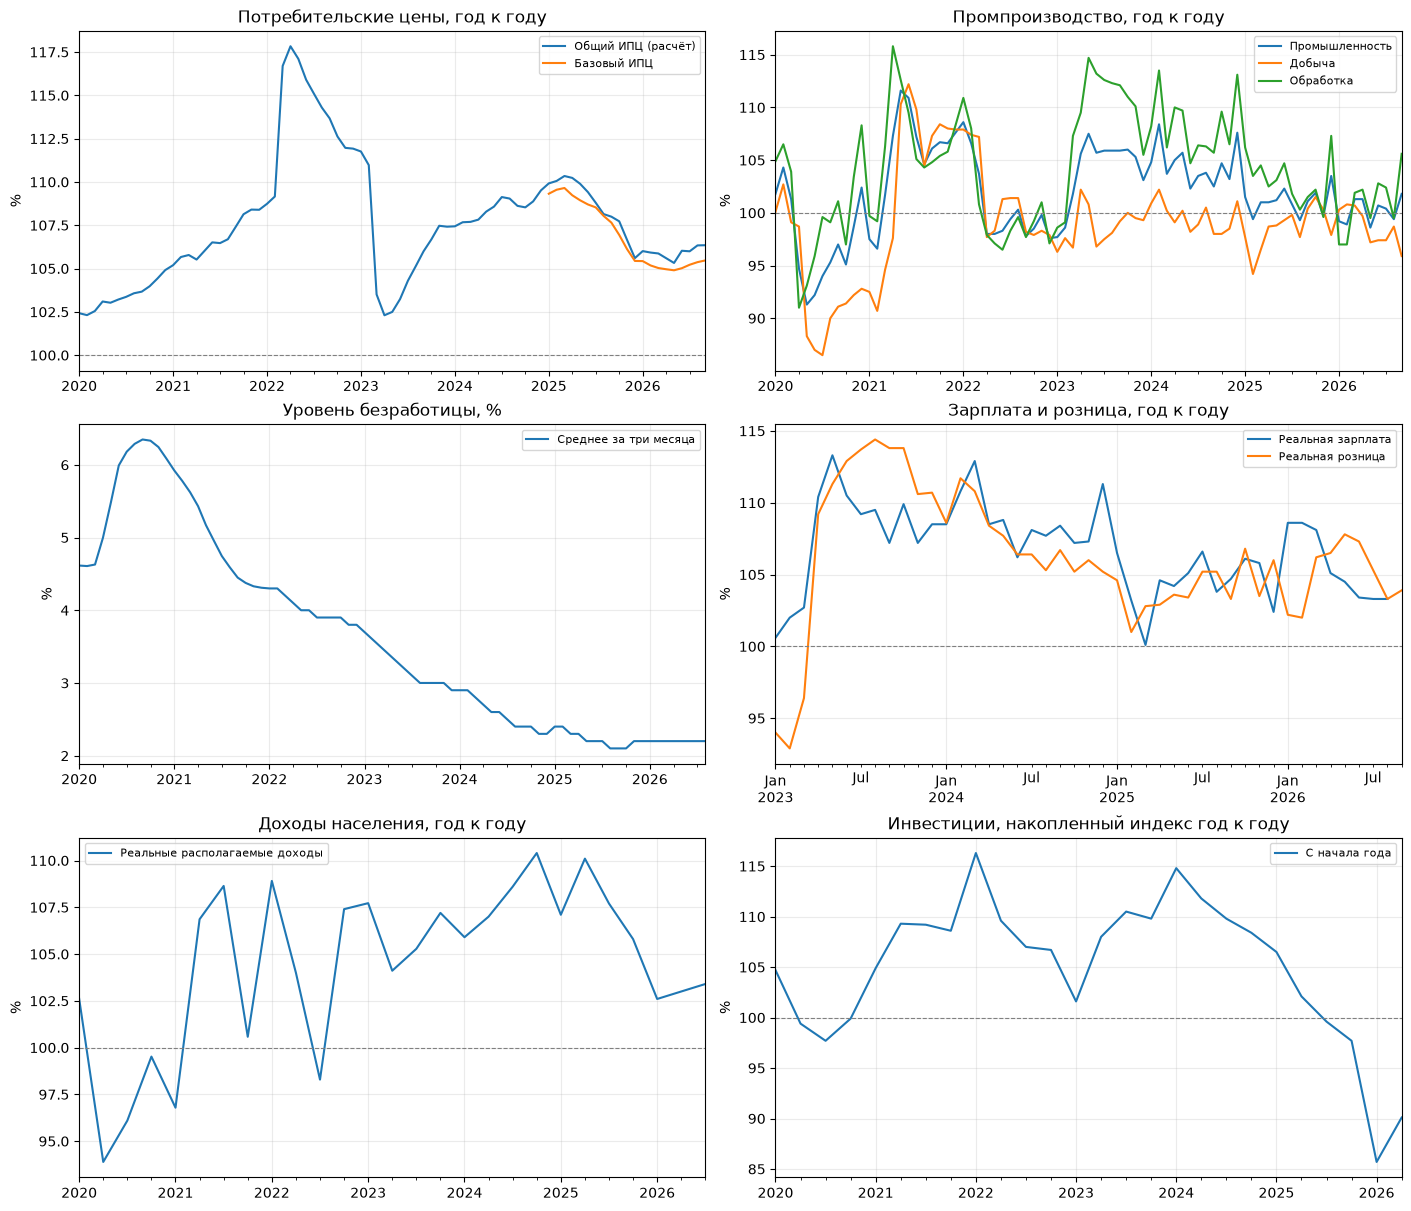

,indicator,period,value,unit,basis,release_date
0,core_cpi_mom_index,2026-09-01,1.004900e+02,%,предыдущий месяц = 100,2026-10-09
1,core_cpi_yoy_index,2026-09-01,1.054700e+02,%,соответствующий месяц предыдущего года = 100,2026-10-09
2,cpi_food_mom_index,2026-09-01,1.000000e+02,%,предыдущий месяц = 100,NaT
3,cpi_mom_index,2026-09-01,1.003500e+02,%,предыдущий месяц = 100,NaT
4,cpi_nonfood_mom_index,2026-09-01,1.005500e+02,%,предыдущий месяц = 100,NaT
5,cpi_services_mom_index,2026-09-01,1.005800e+02,%,предыдущий месяц = 100,NaT
6,gdp_real_2021_bln_rub,2026-04-01,3.550183e+04,млрд рублей,постоянные цены 2021 года,NaT
7,gdp_real_2021_sa_bln_rub,2026-04-01,3.694709e+04,млрд рублей,"постоянные цены 2021 года, сезонная корректировка",NaT
8,gdp_volume_yoy_index,2026-04-01,1.013103e+02,%,соответствующий квартал предыдущего года = 100,NaT
9,investment_real_ytd_yoy_index,2026-04-01,9.010000e+01,%,период с начала года к соответствующему период...,NaT


Графики и расчётные ряды сохранены в /Users/oleynik_n_a/Documents/ChatGPT/Годовой проект/data/processed/20261029T220657790261Z


In [18]:
monthly = matrices['monthly']
quarterly = matrices['quarterly']
cpi_yoy_approx = monthly['cpi_mom_index'].div(100).rolling(12, min_periods=12).apply(
    lambda window: window.prod(), raw=True).mul(100)
wages_yoy = monthly['nominal_wages_rub'].div(monthly['nominal_wages_rub'].shift(12)).mul(100)
analysis = pd.DataFrame({'cpi_yoy_approx_index': cpi_yoy_approx,
                         'nominal_wages_yoy_index': wages_yoy})
analysis.to_csv(OUT / 'derived_monthly_for_analysis.csv', date_format='%Y-%m-%d')

fig, axes = plt.subplots(3, 2, figsize=(14, 12), constrained_layout=True)
start = '2020-01-01'
panels = [
    (axes[0, 0], [(cpi_yoy_approx, 'Общий ИПЦ (расчёт)'),
                  (monthly['core_cpi_yoy_index'], 'Базовый ИПЦ')], 'Потребительские цены, год к году', True),
    (axes[0, 1], [(monthly['production_industry_yoy_index'], 'Промышленность'),
                  (monthly['production_mining_yoy_index'], 'Добыча'),
                  (monthly['production_manufacturing_yoy_index'], 'Обработка')], 'Промпроизводство, год к году', True),
    (axes[1, 0], [(monthly['unemployment_rate_3month_pct'], 'Среднее за три месяца')], 'Уровень безработицы, %', False),
    (axes[1, 1], [(monthly['real_wages_yoy_index'], 'Реальная зарплата'),
                  (monthly['retail_real_yoy_index'], 'Реальная розница')], 'Зарплата и розница, год к году', True),
    (axes[2, 0], [(quarterly['real_disposable_income_yoy_index'], 'Реальные располагаемые доходы')],
     'Доходы населения, год к году', True),
    (axes[2, 1], [(quarterly['investment_real_ytd_yoy_index'], 'С начала года')],
     'Инвестиции, накопленный индекс год к году', True),
]
for ax, series_list, title, is_index in panels:
    for series, label in series_list:
        series.loc[start:].dropna().plot(ax=ax, label=label)
    if is_index:
        ax.axhline(100, color='grey', linewidth=0.8, linestyle='--')
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('%')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.savefig(OUT / 'macro_overview.png', dpi=160, bbox_inches='tight')
plt.show()

latest = (macro.dropna(subset=['value']).sort_values('period').groupby('indicator').tail(1)
          [['indicator', 'period', 'value', 'unit', 'basis', 'release_date']]
          .sort_values('indicator').reset_index(drop=True))
display(latest)
print('Графики и расчётные ряды сохранены в', OUT)

## Краткие наблюдения

Сравниваем последние доступные значения с тем же периодом год назад; все изменения
индексов указаны в процентных пунктах. Это описание рядов, а не вывод о влиянии на ставку ЦБ.

In [19]:
def describe_index(series, label, quarterly=False):
    series = series.dropna()
    period, value = series.index[-1], series.iloc[-1]
    label_period = f'{period.year} Q{period.quarter}' if quarterly else f'{period:%Y-%m}'
    previous = period - pd.DateOffset(years=1)
    if previous in series.index:
        delta = value - series.loc[previous]
        print(f'{label}: {label_period} — {value:.2f}% к тому же периоду прошлого года; '
              f'относительно показателя годом ранее: {delta:+.2f} п. п.')
    else:
        print(f'{label}: {label_period} — {value:.2f}% к тому же периоду прошлого года; '
              'сопоставимое значение год назад отсутствует.')

describe_index(cpi_yoy_approx, 'Общий ИПЦ (расчёт)')
describe_index(monthly['core_cpi_yoy_index'], 'Базовый ИПЦ')
describe_index(monthly['production_industry_yoy_index'], 'Промпроизводство')
describe_index(monthly['retail_real_yoy_index'], 'Реальный оборот розницы')
describe_index(monthly['real_wages_yoy_index'], 'Реальная зарплата')
describe_index(quarterly['real_disposable_income_yoy_index'], 'Реальные располагаемые доходы', quarterly=True)
unemployment = monthly['unemployment_rate_3month_pct'].loc['2020':].dropna()
print(f'Безработица: пик с 2020 года — {unemployment.max():.2f}% '
      f'({unemployment.idxmax():%Y-%m}); последнее значение — {unemployment.iloc[-1]:.2f}% '
      f'({unemployment.index[-1]:%Y-%m}), оба значения — средние за три месяца.')

Общий ИПЦ (расчёт): 2026-09 — 106.35% к тому же периоду прошлого года; относительно показателя годом ранее: -1.65 п. п.
Базовый ИПЦ: 2026-09 — 105.47% к тому же периоду прошлого года; относительно показателя годом ранее: -2.18 п. п.
Промпроизводство: 2026-09 — 101.80% к тому же периоду прошлого года; относительно показателя годом ранее: +0.70 п. п.
Реальный оборот розницы: 2026-09 — 103.90% к тому же периоду прошлого года; относительно показателя годом ранее: +0.60 п. п.
Реальная зарплата: 2026-08 — 103.30% к тому же периоду прошлого года; относительно показателя годом ранее: -0.50 п. п.
Реальные располагаемые доходы: 2026 Q3 — 103.40% к тому же периоду прошлого года; относительно показателя годом ранее: -4.30 п. п.
Безработица: пик с 2020 года — 6.35% (2020-09); последнее значение — 2.20% (2026-08), оба значения — средние за три месяца.


## Подготовка 28 признаков: одно представление каждого ряда

Для будущей классификации решений ЦБ (повышение / снижение / сохранение ставки)
оставляем **ровно один признак на каждый из 28 исходных рядов**:
**23 месячных и 5 квартальных**. Исходные значения отдельно сохранены в
`macro_long.csv`, `macro_monthly.csv` и `macro_quarterly.csv`.
Дополнительные исходные копии, альтернативные представления и столбцы лагов
в таблицы признаков не включаются. Модель и сопоставление с решениями здесь не создаются.

Согласованные преобразования:

- Четыре ряда ИПЦ и три ряда цен производителей → годовые темпы, рассчитанные
  цепочкой из **12 подряд идущих месячных индексов**. Расчёт по округлённым индексам
  и изменения методологии могут давать отличия от официальных годовых темпов.
- Месячный базовый ИПЦ → средняя месячная базовая инфляция за три месяца;
  годовой базовый ИПЦ → годовая базовая инфляция.
- Месячные индексы производства, реальной розницы и платных услуг → месячный рост;
  годовые индексы этих показателей, реальной зарплаты и доходов → годовой рост.
  Для индекса с базой 100 темп равен `I - 100`: `105 → +5%`.
- Номинальная зарплата → годовой рост; номинальная розница → месячный рост.
- Уровень реального ВВП → изменение его годового темпа роста относительно
  предыдущего квартала, в п.п.; сезонно скорректированный ВВП → квартальный рост;
  годовой индекс ВВП → годовой рост.
- Инвестиции → рост с начала года к тому же периоду прошлого года, **не отдельный квартал**;
  безработица → исходный уровень, усреднённый за три месяца.

Окна и сдвиги внутри формул отсчитываются по календарю. Без достаточной истории
значение пустое; пропуски не заполняются. Обе сетки начинаются с **1991 года**.
Месячные изменения сохраняют сезонность источников; собственная сезонная корректировка
не оценивается. Только соответствующий исходный ряд ВВП уже скорректирован Росстатом.
Номинальная розница включает изменение цен; в текущем срезе её месячный рост
доступен за восемь из девяти месяцев.

Результаты в папке текущего запуска:

- `features_monthly.csv` — `period` и 23 месячных признака;
- `features_quarterly.csv` — `period` и 5 квартальных признаков;
- `feature_catalog.csv` — ровно 28 соответствий «исходный ряд → признак», единицы и формулы;
- `feature_coverage.csv` — заполненность и границы доступных значений.

`period` — период наблюдения. При последующем сопоставлении с решениями ЦБ
нужно отдельно учесть даты публикаций и версии использованных данных.


In [20]:
FEATURE_START = '1991-01-01'

# Ровно один согласованный признак на каждый исходный ряд.
# Порядок соответствует согласованному списку; месяцы и кварталы выгружаются отдельно.
FEATURE_SPECS = {
    'cpi_mom_index': ('chain12', 'Годовая общая инфляция, расчётная'),
    'cpi_food_mom_index': ('chain12', 'Годовая продовольственная инфляция, расчётная'),
    'cpi_nonfood_mom_index': ('chain12', 'Годовая непродовольственная инфляция, расчётная'),
    'cpi_services_mom_index': ('chain12', 'Годовая инфляция услуг, расчётная'),
    'core_cpi_mom_index': ('mean3', 'Средняя месячная базовая инфляция за три месяца'),
    'core_cpi_yoy_index': ('index_yoy', 'Годовая базовая инфляция'),
    'ppi_industry_mom_index': ('chain12', 'Годовой рост цен производителей: промышленность, расчётный'),
    'ppi_manufacturing_mom_index': ('chain12', 'Годовой рост цен производителей: обработка, расчётный'),
    'ppi_mining_mom_index': ('chain12', 'Годовой рост цен производителей: добыча, расчётный'),
    'production_industry_mom_index': ('index_mom', 'Месячный рост промпроизводства'),
    'production_industry_yoy_index': ('index_yoy', 'Годовой рост промпроизводства'),
    'production_manufacturing_mom_index': ('index_mom', 'Месячный рост выпуска обработки'),
    'production_manufacturing_yoy_index': ('index_yoy', 'Годовой рост выпуска обработки'),
    'production_mining_mom_index': ('index_mom', 'Месячный рост добычи'),
    'production_mining_yoy_index': ('index_yoy', 'Годовой рост добычи'),
    'gdp_real_2021_bln_rub': ('gdp_acceleration', 'Изменение годового темпа роста ВВП за квартал'),
    'gdp_real_2021_sa_bln_rub': ('gdp_qoq', 'Квартальный рост сезонно скорректированного ВВП'),
    'gdp_volume_yoy_index': ('index_yoy', 'Годовой рост реального ВВП'),
    'investment_real_ytd_yoy_index': ('investment_ytd', 'Рост инвестиций с начала года к тому же периоду прошлого года'),
    'unemployment_rate_3month_pct': ('level', 'Уровень безработицы: среднее за три месяца'),
    'nominal_wages_rub': ('wages_yoy', 'Годовой рост номинальной зарплаты'),
    'real_wages_yoy_index': ('index_yoy', 'Годовой рост реальной зарплаты'),
    'real_disposable_income_yoy_index': ('index_yoy', 'Годовой рост реальных располагаемых доходов'),
    'retail_turnover_nominal_mln_rub': ('retail_mom', 'Месячный рост номинального оборота розницы'),
    'retail_real_mom_index': ('index_mom', 'Месячный рост реального оборота розницы'),
    'retail_real_yoy_index': ('index_yoy', 'Годовой рост реального оборота розницы'),
    'paid_services_volume_mom_index': ('index_mom', 'Месячный рост физического объёма платных услуг'),
    'paid_services_volume_yoy_index': ('index_yoy', 'Годовой рост физического объёма платных услуг'),
}


def growth_pct(series, periods):
    previous = series.shift(periods)
    # Сдвиг по календарной сетке; отсутствующие и неположительные базы не заполняются.
    return (series.div(previous.where(previous.gt(0))) - 1).mul(100)


def build_feature_tables(source_matrices, observations, start=FEATURE_START):
    metadata = observations.groupby('indicator', sort=False).first()
    actual_sources = [column for frame in source_matrices.values() for column in frame.columns]
    if len(actual_sources) != len(set(actual_sources)) or set(actual_sources) != set(FEATURE_SPECS):
        raise ValueError(f'Изменился набор исходных рядов: {set(actual_sources) ^ set(FEATURE_SPECS)}')

    # Суффикс, расчёт, формула, единица, число предыдущих периодов и примечание.
    transforms = {
        'chain12': ('yoy_chained_pct', lambda s: s.div(100).rolling(12, min_periods=12).apply(
            lambda window: window.prod(), raw=True).sub(1).mul(100),
            '100 * (product(I[t-k] / 100, k=0..11) - 1)', '%', 11,
            'Расчётный годовой темп по округлённым месячным индексам.'),
        'mean3': ('mom_mean_3m_pct', lambda s: s.sub(100).rolling(3, min_periods=3).mean(),
            'mean(I[t]-100, I[t-1]-100, I[t-2]-100)', '%', 2,
            'Арифметическое среднее месячных темпов; без сезонной корректировки.'),
        'index_mom': ('mom_pct', lambda s: s - 100, 'I[t] - 100', '%', 0,
            'Месячное изменение; без сезонной корректировки.'),
        'index_yoy': ('yoy_pct', lambda s: s - 100, 'I[t] - 100', '%', 0, ''),
        'wages_yoy': ('yoy_pct', lambda s: growth_pct(s, 12),
            '100 * (x[t] / x[t-12] - 1)', '%', 12, ''),
        'retail_mom': ('mom_pct', lambda s: growth_pct(s, 1),
            '100 * (x[t] / x[t-1] - 1)', '%', 1,
            'Номинальный рост включает изменение цен; без сезонной корректировки.'),
        'gdp_acceleration': ('yoy_change_1q_pp', lambda s: growth_pct(s, 4).diff(1),
            '100 * (x[t] / x[t-4] - x[t-1] / x[t-5])', 'п.п.', 5,
            'Разность годовых темпов текущего и предыдущего кварталов.'),
        'gdp_qoq': ('qoq_pct', lambda s: growth_pct(s, 1),
            '100 * (x[t] / x[t-1] - 1)', '%', 1,
            'Использована сезонная корректировка источника; ряд может пересматриваться.'),
        'investment_ytd': ('ytd_yoy_pct', lambda s: s - 100, 'I_ytd[t] - 100', '%', 0,
            'I квартал / полугодие / 9 месяцев / год; не отдельный квартал.'),
        'level': ('', lambda s: s.copy(), 'x[t]', '%', 0,
            'Доля рабочей силы, среднее за три месяца; не индекс с базой 100.'),
    }
    tables, catalog = {}, []
    for frequency, original in source_matrices.items():
        calendar = pd.date_range(start, original.index.max(),
                                 freq={'monthly': 'MS', 'quarterly': 'QS'}[frequency], name='period')
        raw, columns = original.reindex(calendar), {}
        for source, (method, description) in FEATURE_SPECS.items():
            if source not in raw.columns:
                continue
            info = metadata.loc[source]
            if info.frequency != frequency:
                raise ValueError(f'Несовпадение частоты: {source}')
            suffix, calculate, formula, unit, lookback, note = transforms[method]
            feature = f'{source}__{suffix}' if suffix else source
            columns[feature] = calculate(raw[source]).astype(float)
            catalog.append(dict(feature=feature, frequency=frequency, sources=source,
                                description=description, formula=formula, unit=unit,
                                lookback_periods=lookback,
                                note=' '.join(part for part in [note, info.methodology_note] if part)))
        table = pd.DataFrame(columns, index=calendar)
        if len(table.columns) != len(original.columns) or table.isin([float('inf'), -float('inf')]).any().any():
            raise ValueError(f'Неверное число признаков или бесконечные значения: {frequency}')
        tables[frequency] = table
    catalog = pd.DataFrame(catalog)
    if len(catalog) != 28 or catalog.sources.duplicated().any() or catalog.feature.duplicated().any():
        raise ValueError('Должно быть ровно 28 признаков: один на каждый исходный ряд')
    return tables, catalog


feature_tables, feature_catalog = build_feature_tables(matrices, macro)
coverage_rows = []
for frequency, frame in feature_tables.items():
    frame.to_csv(OUT / f'features_{frequency}.csv', date_format='%Y-%m-%d')
    for feature, series in frame.items():
        coverage_rows.append(dict(feature=feature, frequency=frequency,
                                  start=series.first_valid_index(), end=series.last_valid_index(),
                                  observed=int(series.notna().sum()), missing=int(series.isna().sum())))
feature_coverage = pd.DataFrame(coverage_rows)
feature_catalog.to_csv(OUT / 'feature_catalog.csv', index=False)
feature_coverage.to_csv(OUT / 'feature_coverage.csv', index=False, date_format='%Y-%m-%d')

display(pd.DataFrame([dict(frequency=frequency, periods=len(frame), features=len(frame.columns))
                      for frequency, frame in feature_tables.items()]))
display(feature_catalog[['sources', 'feature', 'description', 'unit', 'formula']])
print('Согласованный набор:', len(feature_catalog), 'признаков из', feature_catalog.sources.nunique(), 'рядов')
print('Полностью пустых признаков:', (feature_coverage.observed == 0).sum())
print('Исходные данные сохранены отдельно в macro_long.csv, macro_monthly.csv и macro_quarterly.csv')
print('Признаки, справочник и покрытие сохранены в', OUT)


frequency,periods,features
monthly,429,23
quarterly,143,5


sources,feature,description,unit,formula
cpi_mom_index,cpi_mom_index__yoy_chained_pct,"Годовая общая инфляция, расчётная",%,"100 * (product(I[t-k] / 100, k=0..11) - 1)"
cpi_food_mom_index,cpi_food_mom_index__yoy_chained_pct,"Годовая продовольственная инфляция, расчётная",%,"100 * (product(I[t-k] / 100, k=0..11) - 1)"
cpi_nonfood_mom_index,cpi_nonfood_mom_index__yoy_chained_pct,"Годовая непродовольственная инфляция, расчётная",%,"100 * (product(I[t-k] / 100, k=0..11) - 1)"
cpi_services_mom_index,cpi_services_mom_index__yoy_chained_pct,"Годовая инфляция услуг, расчётная",%,"100 * (product(I[t-k] / 100, k=0..11) - 1)"
core_cpi_mom_index,core_cpi_mom_index__mom_mean_3m_pct,Средняя месячная базовая инфляция за три месяца,%,"mean(I[t]-100, I[t-1]-100, I[t-2]-100)"
core_cpi_yoy_index,core_cpi_yoy_index__yoy_pct,Годовая базовая инфляция,%,I[t] - 100
ppi_industry_mom_index,ppi_industry_mom_index__yoy_chained_pct,"Годовой рост цен производителей: промышленность, расчётный",%,"100 * (product(I[t-k] / 100, k=0..11) - 1)"
ppi_manufacturing_mom_index,ppi_manufacturing_mom_index__yoy_chained_pct,"Годовой рост цен производителей: обработка, расчётный",%,"100 * (product(I[t-k] / 100, k=0..11) - 1)"
ppi_mining_mom_index,ppi_mining_mom_index__yoy_chained_pct,"Годовой рост цен производителей: добыча, расчётный",%,"100 * (product(I[t-k] / 100, k=0..11) - 1)"
production_industry_mom_index,production_industry_mom_index__mom_pct,Месячный рост промпроизводства,%,I[t] - 100


Согласованный набор: 28 признаков из 28 рядов
Полностью пустых признаков: 0
Исходные данные сохранены отдельно в macro_long.csv, macro_monthly.csv и macro_quarterly.csv
Признаки, справочник и покрытие сохранены в /Users/oleynik_n_a/Documents/ChatGPT/Годовой проект/data/processed/20261029T220657790261Z
